# Extended Data Fig. 13: CA1 d2 vs cross-region coupling (CCA), beginning of learning

80 ms bins is used here because of cell numbers. 

Three analyses of the **beginning** windows (first 5 min of each maze epoch):
1. **Scatter**: CA1 d2 vs CCA, both z-scored within session (as the MATLAB figure), robust linear fit.
2. **GLM coefficients with a hierarchical bootstrap**: CA1 d2 ~ CCA + speed + CA1 pyr rate + CA1 int rate.
3. **Gain from CCA in 10% hold-out cross-validation**: adding CCA improve the prediction of CA1 d2

In [1]:
import os
import warnings
import zlib

import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

DATA = '../csv/FigS13_cca_d2/cca_d2_report_data.csv'
FIGDIR = '../figure_output/supplementary/FigS13'
os.makedirs(FIGDIR, exist_ok=True)
for f in ['Regular', 'Bold']:   # Helvetica clone (Nimbus Sans), embedded as TrueType in the PDF
    fm.fontManager.addfont(f'fonts/NimbusSans-{f}.ttf')

REGIONS = ['CA2', 'CA3', 'MEC']
PREDICTORS = {'cca': 'CCA', 'speed': 'speed', 'fr_pyr': 'CA1 pyr rate', 'fr_int': 'CA1 int rate'}
N_BOOT = 5000                  # hierarchical bootstrap resamples
N_SPLIT, N_PERM = 500, 500     # hold-out splits; CCA shuffles for the p value
TEST_FRAC = 0.10               # fraction of windows held out in each split

df = pd.read_csv(DATA)

## 1. Scatter: CA1 d2 vs CCA (beginning windows)
d2 and CCA z-scored within each session over all its windows (beginning and end), then the
beginning windows plotted. Fit: robust linear regression (Tukey bisquare, MATLAB `fitlm(..., 'RobustOpts', 'on')`);
R² from the robust weights; Kendall τ.

In [2]:
def zscore_by_session(d, cols):
    g = d.groupby(['animal', 'day'])[cols]
    return (d[cols] - g.transform('mean')) / g.transform('std')


def robust_fit(x, y):
    res = sm.RLM(y, sm.add_constant(x), M=sm.robust.norms.TukeyBiweight(4.685)).fit()
    w = res.weights
    y_mean = np.sum(w * y) / np.sum(w)
    r2 = 1 - np.sum(w * res.resid ** 2) / np.sum(w * (y - y_mean) ** 2)
    return res, r2


scatter, rows = {}, []
for r in REGIONS:
    z = zscore_by_session(df, ['d2', f'cca_{r}'])
    keep = (df.phase == 'beginning') & z.notna().all(axis=1)
    x, y = z.loc[keep, f'cca_{r}'].to_numpy(), z.loc[keep, 'd2'].to_numpy()
    res, r2 = robust_fit(x, y)
    tau, p_tau = stats.kendalltau(x, y)
    scatter[r] = (x, y, res)
    d = df[keep]
    rows.append({'region': r, 'animals': d.animal.nunique(), 'sessions': d.groupby(['animal', 'day']).ngroups,
                 'windows': len(x), 'slope': res.params[1], 'SE': res.bse[1], 'p': res.pvalues[1], 'R2': r2,
                 'tau': tau, 'p_tau': p_tau})
scatter_stats = pd.DataFrame(rows)

## 2. GLM with a hierarchical bootstrap
Per region, the beginning windows with that region's CCA: CA1 d2 ~ CCA + speed + CA1 pyr rate + CA1 int rate,
every variable z-scored within session (windows without speed: speed = 0 and a 0/1 "has speed" term).
**Hierarchical bootstrap** (5000×): resample animals, then sessions within each drawn animal, then windows within each
drawn session (all with replacement), refit the GLM; the spread of each coefficient over the resamples is its
uncertainty. p (two-sided) = 2 × the fraction of resamples on the other side of 0.

In [3]:
def glm_data(r):
    """Beginning windows with region r's CCA; within-session z-scores (y = CA1 d2)."""
    d = df[df.phase == 'beginning'].dropna(subset=['d2', f'cca_{r}', 'fr_pyr', 'fr_int'])
    cols = ['d2', f'cca_{r}', 'fr_pyr', 'fr_int', 'speed']
    z = zscore_by_session(d, cols).rename(columns={'d2': 'y', f'cca_{r}': 'cca'})
    z['has_speed'] = z['speed'].notna().astype(float)
    z['speed'] = z['speed'].fillna(0.0)
    z['animal'], z['session'] = d['animal'], d['animal'] + '_' + d['day'].astype(str)
    return z.dropna()


def terms(z, drop=()):
    """Predictors (+ has_speed) that vary in this data."""
    return [t for t in list(PREDICTORS) + ['has_speed'] if t not in drop and z[t].nunique() > 1]


def design(z, cols):
    return np.c_[np.ones(len(z)), z[cols].to_numpy(float)]


def hierarchical_bootstrap(z, n_boot, seed):
    """Coefficients of the full GLM over resamples: animals -> sessions -> windows."""
    rng = np.random.default_rng(seed)
    xs = terms(z)
    X, y = design(z, xs), z['y'].to_numpy(float)
    sess_id = z['session'].to_numpy()
    tree = {a: [np.flatnonzero((z['animal'] == a).to_numpy() & (sess_id == s))
                for s in z.loc[z['animal'] == a, 'session'].unique()] for a in z['animal'].unique()}
    animals = list(tree)
    coef = {p: np.full(n_boot, np.nan) for p in xs}
    for b in range(n_boot):
        idx = []
        for a in rng.choice(len(animals), len(animals)):                 # animals
            sessions = tree[animals[a]]
            for s in rng.choice(len(sessions), len(sessions)):           # sessions of that animal
                rows = sessions[s]
                idx.append(rows[rng.integers(0, len(rows), len(rows))])  # windows of that session
        idx = np.concatenate(idx)
        if len(idx) < len(xs) + 2 or y[idx].std() == 0:
            continue
        beta = np.linalg.lstsq(X[idx], y[idx], rcond=None)[0]
        for j, p in enumerate(xs):
            coef[p][b] = beta[j + 1]
    return coef


def boot_p(v):
    v = v[np.isfinite(v)]
    return max(2 * min(np.mean(v <= 0), np.mean(v >= 0)), 1 / len(v))


boot, rows = {}, []
for r in REGIONS:
    z = glm_data(r)
    xs = terms(z)
    beta_all = np.linalg.lstsq(design(z, xs), z['y'].to_numpy(float), rcond=None)[0]   # all-data GLM
    coef = hierarchical_bootstrap(z, N_BOOT, seed=zlib.crc32(f'matlab|beginning|d2_2024@80|{r}'.encode()))
    boot[r] = (coef, dict(zip(xs, beta_all[1:])))
    for p in PREDICTORS:
        rows.append({'region': r, 'predictor': PREDICTORS[p], 'windows': len(z), 'sessions': z.session.nunique(),
                     'all-data coef': boot[r][1][p], 'bootstrap mean': np.nanmean(coef[p]),
                     'CI 2.5%': np.nanpercentile(coef[p], 2.5), 'CI 97.5%': np.nanpercentile(coef[p], 97.5),
                     'p': boot_p(coef[p])})
boot_stats = pd.DataFrame(rows)

## 3. Gain from CCA in 10% hold-out cross-validation
In each of 500 splits, a random 10% of the windows is the test set. Two models are fitted (least squares) on the other
90%: **full** (CCA + speed + rates) and **without CCA** (speed + rates). Each is scored on the test windows:
test R² = 1 − mean squared error / variance of CA1 d2 (over all windows). **Gain** = test R² (full) − test R² (without
CCA): how much adding CCA improves the prediction of unseen windows.
p: CCA shuffled across the windows of each session (500 times, same splits); p = fraction of shuffles whose mean gain
is ≥ the real one (one-sided; smallest possible 1/501 ≈ 0.002).

In [4]:
def test_r2(X, y, train, test, var_y):
    beta = np.linalg.lstsq(X[train], y[train], rcond=None)[0]
    return 1 - np.mean((y[test] - X[test] @ beta) ** 2) / var_y


def holdout_gain(z, seed):
    rng = np.random.default_rng(seed)
    y = z['y'].to_numpy(float)
    n, var_y = len(y), y.var()
    n_test = max(3, round(TEST_FRAC * n))
    xs = terms(z)
    X_full, X_no = design(z, xs), design(z, terms(z, drop=('cca',)))
    splits = []
    for _ in range(N_SPLIT):
        order = rng.permutation(n)
        splits.append((np.sort(order[n_test:]), order[:n_test]))         # (train, test)
    r2_no = np.array([test_r2(X_no, y, tr, te, var_y) for tr, te in splits])
    gain = np.array([test_r2(X_full, y, tr, te, var_y) for tr, te in splits]) - r2_no

    # null: CCA shuffled within session, same splits
    c = 1 + xs.index('cca')
    sessions = [np.flatnonzero(z['session'].to_numpy() == s) for s in z['session'].unique()]
    null = np.empty(N_PERM)
    for k in range(N_PERM):
        Xs = X_full.copy()
        for idx in sessions:
            Xs[idx, c] = Xs[rng.permutation(idx), c]
        null[k] = np.mean([test_r2(Xs, y, tr, te, var_y) for tr, te in splits] - r2_no)
    return gain, (1 + np.sum(null >= gain.mean())) / (1 + N_PERM), n_test


cv, rows = {}, []
for r in REGIONS:
    z = glm_data(r)
    gain, p, n_test = holdout_gain(z, seed=zlib.crc32(f'holdout|{r}'.encode()))
    cv[r] = (gain, p)
    rows.append({'region': r, 'windows': len(z), 'test windows': n_test, 'mean gain': gain.mean(),
                 'median gain': np.median(gain), '% splits CCA helps': 100 * np.mean(gain > 0), 'p': p})
cv_stats = pd.DataFrame(rows)

## Figure
Top: scatter (orange line: robust fit). 

Middle: GLM coefficients per region (dots: 300 of the 5000 bootstrap
resamples; bar: bootstrap mean; black tick: all-data fit; p: bootstrap, bold < 0.05). 

Bottom: gain from CCA in the
10% hold-out (box: interquartile range, white line: median, whiskers: 2.5–97.5%, dot: mean; p: permutation).

the number might change a little due to the random sampling.

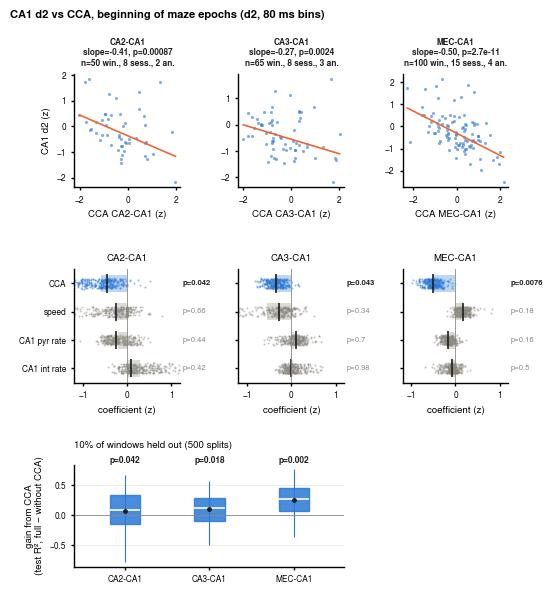

In [5]:
RC = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Nimbus Sans TT', 'Arial'], 'font.size': 7,
      'axes.titlesize': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6, 'ytick.labelsize': 6, 'axes.linewidth': 1,
      'xtick.major.width': 1, 'ytick.major.width': 1, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
      'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False}
BLUE, ORANGE, BLACK, MUTED, GRID = '#2a78d6', '#eb6834', '#1f1f1d', '#8a887f', '#e4e3de'


def p_text(p):
    return dict(color=BLACK if p < 0.05 else MUTED, fontweight='bold' if p < 0.05 else 'normal')


with plt.rc_context(RC):
    fig = plt.figure(figsize=(5.6, 6.4))
    gs = fig.add_gridspec(3, len(REGIONS), height_ratios=[1, 1, 0.9], hspace=0.75, wspace=0.55)

    # row 1: scatter
    for j, r in enumerate(REGIONS):
        ax = fig.add_subplot(gs[0, j])
        x, y, res = scatter[r]
        s = scatter_stats.set_index('region').loc[r]
        ax.scatter(x, y, s=5, color=BLUE, alpha=0.6, lw=0)
        xs = np.linspace(x.min(), x.max(), 20)
        ax.plot(xs, res.params[0] + res.params[1] * xs, color=ORANGE, lw=1.2)
        ax.set_title(f'{r}-CA1\nslope={s.slope:+.2f}, p={s.p:.2g}\nn={int(s.windows)} win., {int(s.sessions)} sess., '
                     f'{int(s.animals)} an.', fontsize=6, linespacing=1.2, **p_text(s.p))
        ax.set_xlabel(f'CCA {r}-CA1 (z)')
        if j == 0:
            ax.set_ylabel('CA1 d2 (z)')

    # row 2: bootstrap coefficients
    preds = list(PREDICTORS)
    for j, r in enumerate(REGIONS):
        ax = fig.add_subplot(gs[1, j])
        coef, beta = boot[r]
        for k, p in enumerate(preds):
            v = coef[p][np.isfinite(coef[p])]
            col = BLUE if p == 'cca' else MUTED
            ax.barh(k, v.mean(), 0.6, color=col, alpha=0.3)
            sub = np.random.default_rng(k).choice(v, min(300, len(v)), replace=False)
            ax.scatter(sub, k + np.random.default_rng(k + 1).uniform(-0.18, 0.18, len(sub)), s=2, color=col, lw=0,
                       alpha=0.5)
            ax.vlines(beta[p], k - 0.32, k + 0.32, color=BLACK, lw=1.2)
            pv = boot_p(v)
            ax.text(1.02, k, f'p={pv:.2g}', transform=ax.get_yaxis_transform(), va='center', fontsize=5.5, **p_text(pv))
        ax.axvline(0, color=MUTED, lw=0.6)
        ax.set_yticks(range(len(preds)), [PREDICTORS[p] for p in preds] if j == 0 else [''] * len(preds))
        ax.invert_yaxis()
        ax.set_xlim(-1.2, 1.2)
        ax.set_xlabel('coefficient (z)')
        ax.set_title(f'{r}-CA1', fontsize=7)

    # row 3: hold-out gain
    ax = fig.add_subplot(gs[2, :2])
    for j, r in enumerate(REGIONS):
        gain, p = cv[r]
        lo, q1, med, q3, hi = np.percentile(gain, [2.5, 25, 50, 75, 97.5])
        ax.vlines(j, lo, hi, color=BLUE, lw=0.8)
        ax.add_patch(plt.Rectangle((j - 0.18, q1), 0.36, q3 - q1, color=BLUE, alpha=0.85))
        ax.hlines(med, j - 0.18, j + 0.18, color='white', lw=1.2)
        ax.plot(j, gain.mean(), 'o', color=BLACK, ms=2.5, zorder=4)
        ax.text(j, 1.02, f'p={p:.2g}', ha='center', fontsize=6, transform=ax.get_xaxis_transform(), **p_text(p))
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_xticks(range(len(REGIONS)), [f'{r}-CA1' for r in REGIONS])
    ax.set_xlim(-0.6, len(REGIONS) - 0.4)
    ax.set_ylabel('gain from CCA\n(test R², full − without CCA)')
    ax.set_title(f'{TEST_FRAC:.0%} of windows held out ({N_SPLIT} splits)', loc='left', pad=12)
    ax.grid(axis='y', color=GRID, lw=0.5)
    ax.set_axisbelow(True)

    fig.suptitle('CA1 d2 vs CCA, beginning of maze epochs (d2, 80 ms bins)', x=0.01, ha='left',
                 fontweight='bold', fontsize=8)
    fig.savefig(f'{FIGDIR}/FigS13_cca_d2_beginning_80ms.pdf', bbox_inches='tight')
    plt.show()